# Experiment 1: Time and frequency domain, and the pendulum
Aniruddh Vijayvargia (500125613), Batch D. Lab Manual, Chapter 2.

The notebook builds a three-tone signal, reads its spectrum, demonstrates
aliasing and spectral leakage, and integrates a damped pendulum.
All figures are written to `figs/` and all measured numbers to `results.json`.

In [1]:
import json, os, platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": {"python": platform.python_version(), "numpy": np.__version__,
                  "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}}
print(R["versions"])

{'python': '3.11.9', 'numpy': '2.4.6', 'scipy': '1.17.1', 'matplotlib': '3.11.2'}


## Part 1: a signal of known composition

{'fs': 500.0, 'T': 2.0, 'N': 1000, 'df': 0.5, 'nyquist': 250.0}


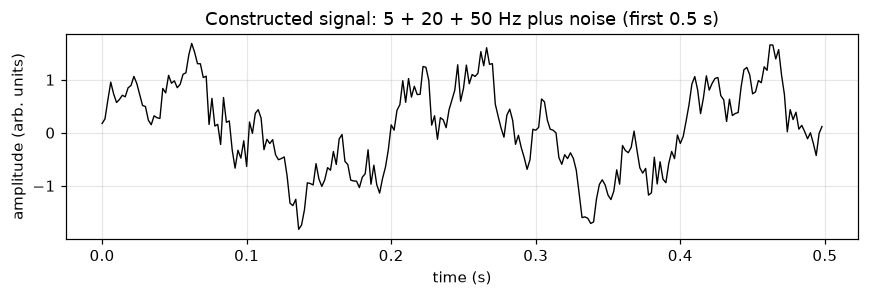

In [2]:
fs, T = 500.0, 2.0                      # sampling rate (Hz), record length (s)
t = np.arange(0, T, 1 / fs)
N = t.size
df = fs / N
COMPONENTS = [(5.0, 1.00), (20.0, 0.50), (50.0, 0.25)]   # (frequency Hz, amplitude)

rng = np.random.default_rng(613)        # seed taken from my SAP ID
x = sum(a * np.sin(2 * np.pi * f * t) for f, a in COMPONENTS) + 0.20 * rng.standard_normal(N)

R["sampling"] = {"fs": fs, "T": T, "N": int(N), "df": df, "nyquist": fs / 2}
print(R["sampling"])

fig, ax = plt.subplots(figsize=(8, 2.8))
m = t < 0.5
ax.plot(t[m], x[m], lw=0.9, color="k")
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude (arb. units)")
ax.set_title("Constructed signal: 5 + 20 + 50 Hz plus noise (first 0.5 s)")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_1_signal.png")

{'set_f': 5.0, 'meas_f': 5.0, 'set_a': 1.0, 'meas_a': 1.000709829548246}
{'set_f': 20.0, 'meas_f': 20.0, 'set_a': 0.5, 'meas_a': 0.4936298644051672}
{'set_f': 50.0, 'meas_f': 50.0, 'set_a': 0.25, 'meas_a': 0.24996166332570635}


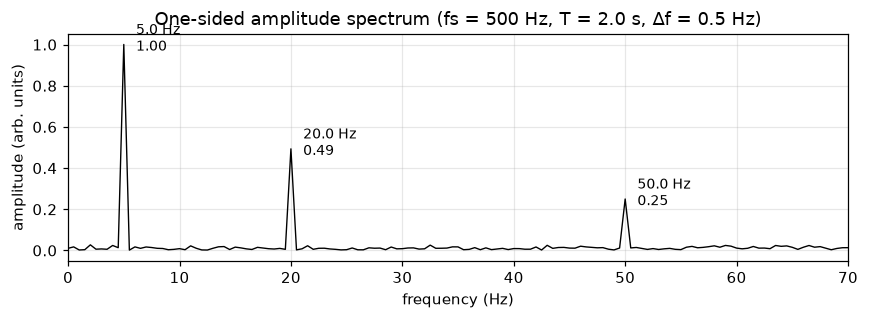

In [3]:
def one_sided_spectrum(sig, fs):
    """Amplitude spectrum scaled so that a peak height equals the sine amplitude."""
    X = np.fft.rfft(sig)
    f = np.fft.rfftfreq(sig.size, d=1 / fs)
    amp = np.abs(X) * 2.0 / sig.size
    amp[0] /= 2.0                        # the DC term is not doubled
    return f, amp

f, amp = one_sided_spectrum(x, fs)
measured = []
for f_set, a_set in COMPONENTS:
    win = (f > f_set - 3) & (f < f_set + 3)
    k = np.argmax(amp * win)
    measured.append({"set_f": f_set, "meas_f": float(f[k]), "set_a": a_set, "meas_a": float(amp[k])})
R["spectrum"] = measured
for r in measured:
    print(r)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f, amp, lw=0.9, color="k")
for r in measured:
    ax.annotate(f"{r['meas_f']:.1f} Hz\n{r['meas_a']:.2f}", (r["meas_f"], r["meas_a"]),
                xytext=(8, -4), textcoords="offset points", fontsize=9)
ax.set_xlim(0, 70)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("amplitude (arb. units)")
ax.set_title(f"One-sided amplitude spectrum (fs = {fs:.0f} Hz, T = {T} s, Δf = {df} Hz)")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_2_spectrum.png")

## Spectral leakage: the same signal with T = 1.7 s

In [4]:
t17 = np.arange(0, 1.7, 1 / fs)
x17 = sum(a * np.sin(2 * np.pi * f_ * t17) for f_, a in COMPONENTS)   # noise-free for clarity
f17, amp17 = one_sided_spectrum(x17, fs)
leak = []
for f_set, a_set in COMPONENTS:
    win = (f17 > f_set - 3) & (f17 < f_set + 3)
    k = np.argmax(amp17 * win)
    leak.append({"set_f": f_set, "peak_f": float(f17[k]), "peak_a": float(amp17[k]),
                 "bins_above_10pct": int(np.sum((amp17 > 0.1 * a_set) & win))})
R["leakage"] = {"T": 1.7, "N": int(t17.size), "df": fs / t17.size, "peaks": leak}
print(R["leakage"])

{'T': 1.7, 'N': 850, 'df': 0.5882352941176471, 'peaks': [{'set_f': 5.0, 'peak_f': 4.705882352941177, 'peak_a': 0.6558866347470635, 'bins_above_10pct': 7}, {'set_f': 20.0, 'peak_f': 20.0, 'peak_a': 0.5000251778420545, 'bins_above_10pct': 1}, {'set_f': 50.0, 'peak_f': 50.0, 'peak_a': 0.2500012219990968, 'bins_above_10pct': 1}]}


## Part 2: aliasing (5 Hz sine sampled at 8 Hz)

aliased peak at 3.0 Hz


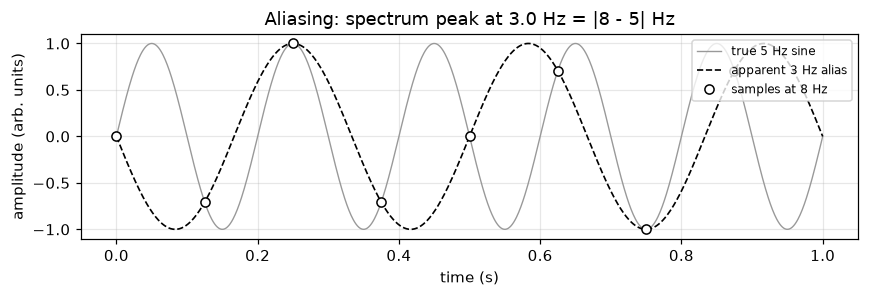

In [5]:
fs_a = 8.0
t_a = np.arange(0, 1.0, 1 / fs_a)
x_a = np.sin(2 * np.pi * 5 * t_a)
f_a = np.fft.rfftfreq(t_a.size, d=1 / fs_a)
alias_peak = float(f_a[np.argmax(np.abs(np.fft.rfft(x_a)))])
R["alias"] = {"fs": fs_a, "f_true": 5.0, "peak": alias_peak, "nyquist": fs_a / 2}
print("aliased peak at", alias_peak, "Hz")

tf = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(tf, np.sin(2 * np.pi * 5 * tf), lw=0.9, color="0.6", label="true 5 Hz sine")
ax.plot(tf, -np.sin(2 * np.pi * 3 * tf), "--", lw=1.1, color="k", label="apparent 3 Hz alias")
ax.plot(t_a, x_a, "o", ms=6, mfc="w", mec="k", label="samples at 8 Hz")
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude (arb. units)")
ax.set_title(f"Aliasing: spectrum peak at {alias_peak:.1f} Hz = |8 - 5| Hz")
ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_3_aliasing.png")

## Part 3: the pendulum

T0 = 2.0061 s


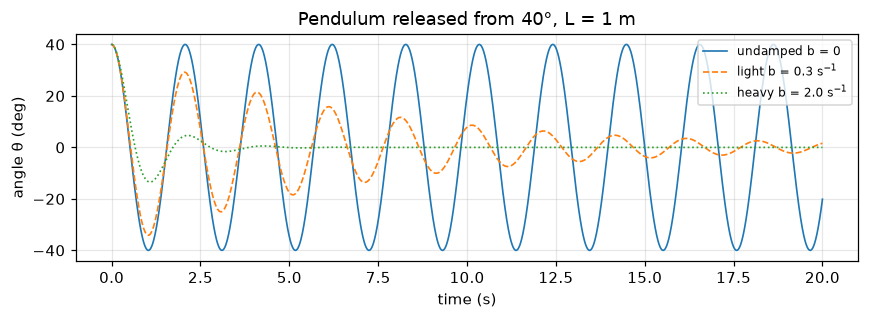

In [6]:
g, L, MASS = 9.81, 1.0, 1.0
T0 = 2 * np.pi * np.sqrt(L / g)
R["pendulum"] = {"g": g, "L": L, "m": MASS, "T0": T0}
print("T0 =", round(T0, 4), "s")

def pendulum(t, y, b):                    # solve_ivp calls f(t, y, *args)
    theta, omega = y
    return [omega, -(b / MASS) * omega - (g / L) * np.sin(theta)]

def simulate(theta0_deg, b, T=20.0, n=4000):
    te = np.linspace(0, T, n)
    sol = solve_ivp(pendulum, [0, T], [np.deg2rad(theta0_deg), 0.0], args=(b,),
                    t_eval=te, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

DAMPING = [(0.0, "undamped b = 0"), (0.3, "light b = 0.3 s$^{-1}$"), (2.0, "heavy b = 2.0 s$^{-1}$")]
R["pendulum"]["damping"] = [b for b, _ in DAMPING]
runs = {b: simulate(40, b) for b, _ in DAMPING}

fig, ax = plt.subplots(figsize=(8, 3))
for (b, lab), ls in zip(DAMPING, ["-", "--", ":"]):
    tt, th, _ = runs[b]
    ax.plot(tt, np.rad2deg(th), ls, lw=1.1, label=lab)
ax.set_xlabel("time (s)"); ax.set_ylabel("angle θ (deg)")
ax.set_title("Pendulum released from 40°, L = 1 m")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_4_pendulum.png")

In [7]:
def period_zero_crossings(tt, th):
    """Mean spacing of upward zero crossings, linearly interpolated in time."""
    s = np.sign(th)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tc = tt[idx] - th[idx] * (tt[idx + 1] - tt[idx]) / (th[idx + 1] - th[idx])
    return float(np.mean(np.diff(tc)))

def period_spectrum(tt, th):
    fs2 = 1 / (tt[1] - tt[0])
    A = np.abs(np.fft.rfft(th))
    fr = np.fft.rfftfreq(th.size, 1 / fs2)
    return float(1 / fr[1:][np.argmax(A[1:])])      # skip bin 0 (the mean)

sweep = np.arange(5, 180, 5)
p_zc, p_sp = [], []
for a in sweep:
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    p_zc.append(period_zero_crossings(tt, th)); p_sp.append(period_spectrum(tt, th))
p_zc, p_sp = np.array(p_zc), np.array(p_sp)
table = [{"angle": int(a), "zc": float(p_zc[sweep == a][0]), "spec": float(p_sp[sweep == a][0]),
          "ratio": float(p_zc[sweep == a][0] / T0)} for a in (5, 45, 95, 135, 175)]
R["period_table"] = table
for r in table:
    print(r)

{'angle': 5, 'zc': 2.00702191356248, 'spec': 2.000166680556713, 'ratio': 1.0004761720340691}
{'angle': 45, 'zc': 2.08625587045496, 'spec': 2.0691379454034964, 'ratio': 1.0399733421203654}
{'angle': 95, 'zc': 2.417384380517158, 'spec': 2.4002000166680557, 'ratio': 1.2050369031904768}
{'angle': 135, 'zc': 3.06516471293285, 'spec': 3.0002500208350695, 'ratio': 1.5279475714371655}
{'angle': 175, 'zc': 5.7727835644372965, 'spec': 6.000500041670139, 'ratio': 2.877662851362594}


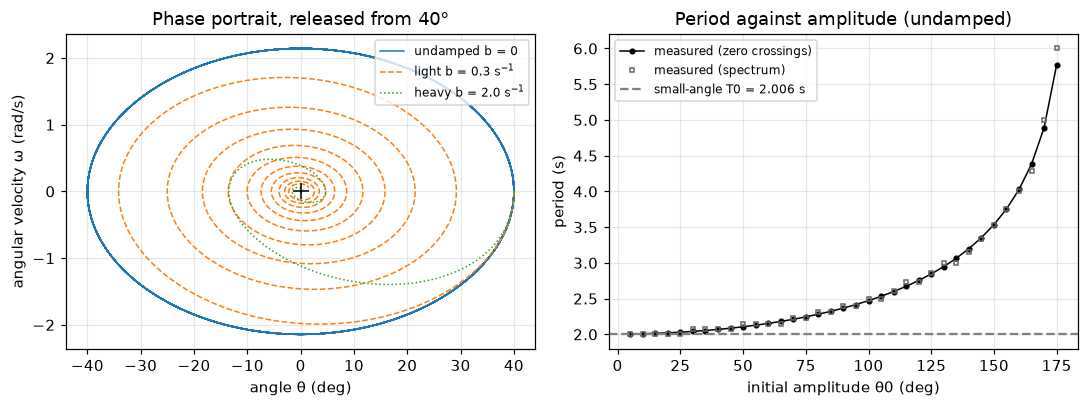

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
for (b, lab), ls in zip(DAMPING, ["-", "--", ":"]):
    _, th, om = runs[b]
    ax1.plot(np.rad2deg(th), om, ls, lw=1.0, label=lab)
ax1.plot(0, 0, "k+", ms=10)
ax1.set_xlabel("angle θ (deg)"); ax1.set_ylabel("angular velocity ω (rad/s)")
ax1.set_title("Phase portrait, released from 40°"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

ax2.plot(sweep, p_zc, "o-", ms=3, lw=1, color="k", label="measured (zero crossings)")
ax2.plot(sweep, p_sp, "s", ms=3, mfc="none", color="0.4", label="measured (spectrum)")
ax2.axhline(T0, ls="--", color="0.5", label=f"small-angle T0 = {T0:.3f} s")
ax2.set_xlabel("initial amplitude θ0 (deg)"); ax2.set_ylabel("period (s)")
ax2.set_title("Period against amplitude (undamped)"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig1_5_phase_period.png")

In [9]:
with open("results.json", "w") as fh:
    json.dump(R, fh, indent=2)
print("saved results.json")

saved results.json
